# Placement 2, part 1: reproducing BiomedCoOp on brain tumour MRI

Before applying BiomedCoOp (Koleilat et al., CVPR 2025) to dementia, I check that the authors' code reproduces their published results. I use BTMRI, the paper's brain MRI dataset (glioma, meningioma, pituitary tumour, normal brain), with their split and settings, and train with 1, 2, 4, 8 and 16 labelled images per class, each with seeds 1, 2 and 3, as in the paper.

The results are compared with Table S8 of the paper's supplementary material.


## 1. Setup

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
# Everything I want to keep (logs, results, figures) goes to Google Drive.
#The datasets and the code live on the Colab disk, which is faster.
PROJECT = '/content/drive/MyDrive/placement2'
OUTPUTS = f'{PROJECT}/outputs'
RESULTS = f'{PROJECT}/results'
DATA = '/content/data'
BIOMEDCOOP = '/content/BiomedCoOp'
for d in (OUTPUTS, RESULTS, f'{RESULTS}/figures', DATA):
    os.makedirs(d, exist_ok=True)

Mounted at /content/drive


In [ ]:
%%bash
# The authors' code, at the commit I used for every experiment.
cd /content
if [ ! -d BiomedCoOp ]; then git clone -q https://github.com/HealthX-Lab/BiomedCoOp.git; fi
cd BiomedCoOp
git checkout -q 23710b0b867e8cb4a5ea95b0ccbaa5e35203db0d
echo "BiomedCoOp at commit $(git rev-parse --short HEAD)"
pip install -q yacs gdown ftfy regex tabulate wilds==1.2.2 open_clip_torch==2.23.0 transformers==4.35.2

# Dassl is the training framework BiomedCoOp is built on.
cd Dassl.pytorch && python -c "import dassl; print('dassl', dassl.__version__)"
python -c "import torch; print('torch', torch.__version__, '| GPU:', torch.cuda.get_device_name(0))"

BiomedCoOp at commit 23710b0
dassl 0.5.0
torch 2.11.0+cu130 | GPU: Tesla T4


In [ ]:
%%bash
cd /content/BiomedCoOp
sed -i 's/super().__init__(optimizer, last_epoch, verbose)/super().__init__(optimizer, last_epoch)/' \
    Dassl.pytorch/dassl/optim/lr_scheduler.py
grep -c "super().__init__(optimizer, last_epoch)" Dassl.pytorch/dassl/optim/lr_scheduler.py

1


## 2. Data

In [ ]:
import json, shutil, zipfile
from huggingface_hub import hf_hub_download

# BTMRI as prepared by the authors (on Hugging Face), with their train/val/test
CLASS_FOLDERS = ['glioma_tumor', 'meningioma_tumor', 'normal_brain', 'pituitary_tumor']
image_dir = f'{DATA}/BTMRI/BTMRI'
split_file = f'{DATA}/BTMRI/split_BTMRI.json'

if not os.path.isdir(image_dir):
    zip_path = hf_hub_download('TahaKoleilat/BiomedCoOp', 'BTMRI.zip', repo_type='dataset')
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(f'{DATA}/_unzip')
    for root, dirs, _ in os.walk(f'{DATA}/_unzip'):
        if all(c in dirs for c in CLASS_FOLDERS):
            os.makedirs(f'{DATA}/BTMRI', exist_ok=True)
            shutil.move(root, image_dir)
            break
    shutil.rmtree(f'{DATA}/_unzip', ignore_errors=True)
if not os.path.exists(split_file):
    shutil.copy(f'{BIOMEDCOOP}/data/BTMRI/split_BTMRI.json', split_file)

# Check that every image listed in the split is on disk.
split = json.load(open(split_file))
missing = [p for part in split.values() for p, _, _ in part if not os.path.exists(f'{image_dir}/{p}')]
print({k: len(v) for k, v in split.items()}, '| missing images:', len(missing))
assert not missing

{'train': 2854, 'val': 1141, 'test': 1717} | missing images: 0


## 3. Helper functions

One function to run any method through the authors' `train.py`, and one to read the results back from the logs.

In [ ]:
import glob, re, subprocess, sys
import numpy as np
import pandas as pd

SHOTS = [1, 2, 4, 8, 16]   # labelled images per class, as in the paper
DASSL = f'{BIOMEDCOOP}/Dassl.pytorch'
ENV = {**os.environ, 'PYTHONPATH': f"{DASSL}:{BIOMEDCOOP}:{os.environ.get('PYTHONPATH', '')}"}

COMMON_OPTS = ['TEST.COMPUTE_CMAT', 'True', 'TEST.PER_CLASS_RESULT', 'True',
               'DATALOADER.NUM_WORKERS', '2']


def run_finished(out_dir):
    """A run counts as done once its log has a test accuracy in it."""
    for log in glob.glob(f'{out_dir}/log.txt*'):
        if '* accuracy:' in open(log, errors='ignore').read():
            return True
    return False


def run(trainer, dataset_cfg, trainer_cfg, out_dir, shots=None, seed=None,
        opts=(), eval_only=False, script=f'{BIOMEDCOOP}/train.py'):
    """Runs one training/test job with the authors' train.py (or my wrapper).

    Only the result lines are printed here, to keep the notebook readable.
    Dassl writes the full output to log.txt in out_dir."""
    if run_finished(out_dir):
        print(f'already done: {out_dir.replace(OUTPUTS + "/", "")}')
        return
    cmd = [sys.executable, script, '--root', DATA, '--trainer', trainer,
           '--dataset-config-file', dataset_cfg, '--config-file', trainer_cfg,
           '--output-dir', out_dir]
    if seed is not None:
        cmd += ['--seed', str(seed)]
    if eval_only:
        cmd += ['--eval-only']
    cmd += list(opts) + COMMON_OPTS
    if shots is not None:
        cmd += ['DATASET.NUM_SHOTS', str(shots)]

    print(f'\n{out_dir.replace(OUTPUTS + "/", "")}')
    proc = subprocess.Popen(cmd, cwd=BIOMEDCOOP, env=ENV, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True)


    tail = []
    for line in proc.stdout:
        tail = (tail + [line])[-40:]
        if line.startswith(('* accuracy', '* macro_f1')):
            print('   ', line.strip())
    if proc.wait() != 0:
        # Stop here instead of carrying on with a broken setup.
        print(''.join(tail))
        raise RuntimeError(f'run failed: {out_dir}')


def read_result(run_dir):
    """Reads the final test metrics back from a run's log."""
    text = ''.join(open(f, errors='ignore').read() for f in sorted(glob.glob(f'{run_dir}/log.txt*')))
    acc = re.findall(r'\* accuracy: ([\d.]+)%', text)
    if not acc:
        return None
    row = {'accuracy': float(acc[-1]),
           'macro_f1': float(re.findall(r'\* macro_f1: ([\d.]+)%', text)[-1])}
    last = text[text.rfind('* macro_f1'):]
    for name, acc_c in re.findall(r'\* class: \d+ \((.+?)\).*?acc: ([\d.]+)%', last):
        row[f'acc_{name}'] = float(acc_c)
    return row


def collect(dataset):
    """All finished runs of one dataset -> (one row per run, mean/std per method and K)."""
    rows = []
    for log in glob.glob(f'{OUTPUTS}/{dataset}/**/log.txt', recursive=True):
        run_dir = os.path.dirname(log)
        res = read_result(run_dir)
        if res is None:
            continue
        parts = os.path.relpath(run_dir, f'{OUTPUTS}/{dataset}').split('/')
        shots = next((int(p[6:]) for p in parts if p.startswith('shots_')), 0)
        seed = next((int(p[4:]) for p in parts if p.startswith('seed')), 0)
        rows.append({'method': parts[0], 'shots': shots, 'seed': seed, **res})
    runs = pd.DataFrame(rows).sort_values(['method', 'shots', 'seed']).reset_index(drop=True)
    metrics = [c for c in runs.columns if c in ('accuracy', 'macro_f1') or c.startswith('acc_')]
    summary = runs.groupby(['method', 'shots'])[metrics].agg(['mean', 'std']).round(2)
    summary.columns = [f'{m}_{s}' for m, s in summary.columns]
    summary.insert(0, 'n_seeds', runs.groupby(['method', 'shots']).size())
    runs.to_csv(f'{RESULTS}/{dataset}_runs.csv', index=False)
    summary.reset_index().to_csv(f'{RESULTS}/{dataset}_summary.csv', index=False)
    return runs, summary.reset_index()

In [ ]:
# BTMRI and KneeXray results reported in the paper's supplementary material
PAPER = pd.DataFrame([
    # dataset, method, K, mean, std
    ('BTMRI', 'zeroshot', 0, 56.79, np.nan), ('BTMRI', 'zeroshot_ensemble', 0, 61.04, np.nan),
    ('BTMRI', 'biomedcoop', 1, 65.08, 1.81), ('BTMRI', 'biomedcoop', 2, 70.57, 4.31),
    ('BTMRI', 'biomedcoop', 4, 77.23, 3.90), ('BTMRI', 'biomedcoop', 8, 78.55, 2.19),
    ('BTMRI', 'biomedcoop', 16, 83.30, 1.34),
    ('BTMRI', 'coop', 1, 63.82, 3.94), ('BTMRI', 'coop', 2, 68.82, 5.15),
    ('BTMRI', 'coop', 4, 74.68, 2.99), ('BTMRI', 'coop', 8, 79.27, 1.90),
    ('BTMRI', 'coop', 16, 82.37, 1.89),
    ('BTMRI', 'linear_probe', 1, 62.24, 5.03), ('BTMRI', 'linear_probe', 2, 72.45, 5.27),
    ('BTMRI', 'linear_probe', 4, 75.98, 1.94), ('BTMRI', 'linear_probe', 8, 77.63, 3.45),
    ('BTMRI', 'linear_probe', 16, 81.24, 2.56),
    ('KneeXray', 'zeroshot', 0, 29.53, np.nan), ('KneeXray', 'zeroshot_ensemble', 0, 39.37, np.nan),
    ('KneeXray', 'biomedcoop', 1, 36.13, 1.75), ('KneeXray', 'biomedcoop', 2, 37.72, 0.54),
    ('KneeXray', 'biomedcoop', 4, 35.91, 0.54), ('KneeXray', 'biomedcoop', 8, 37.70, 1.00),
    ('KneeXray', 'biomedcoop', 16, 39.69, 1.75),
    ('KneeXray', 'coop', 1, 24.96, 9.41), ('KneeXray', 'coop', 2, 25.89, 5.06),
    ('KneeXray', 'coop', 4, 23.85, 4.25), ('KneeXray', 'coop', 8, 26.23, 4.01),
    ('KneeXray', 'coop', 16, 28.48, 1.84),
    ('KneeXray', 'linear_probe', 1, 26.02, 11.08), ('KneeXray', 'linear_probe', 2, 26.57, 5.17),
    ('KneeXray', 'linear_probe', 4, 27.83, 4.92), ('KneeXray', 'linear_probe', 8, 22.20, 3.68),
    ('KneeXray', 'linear_probe', 16, 23.97, 3.55),
], columns=['dataset', 'method', 'shots', 'accuracy_mean', 'accuracy_std'])
PAPER.to_csv(f'{RESULTS}/paper_reference_results.csv', index=False)

In [ ]:
# Configs and trainer names exactly as in the authors' scripts
DATASET_CFG = f'{BIOMEDCOOP}/configs/datasets/btmri.yaml'
ZEROSHOT_CFG = f'{BIOMEDCOOP}/configs/trainers/Zeroshot/vit_b16.yaml'
BIOMEDCOOP_CFG = f'{BIOMEDCOOP}/configs/trainers/BiomedCoOp/few_shot/btmri.yaml'
COOP_CFG = f'{BIOMEDCOOP}/configs/trainers/CoOp/vit_b16.yaml'
BIOMEDCOOP_OPTS = ['TRAINER.BIOMEDCOOP.N_CTX', '4', 'TRAINER.BIOMEDCOOP.CSC', 'False',
                   'TRAINER.BIOMEDCOOP.CLASS_TOKEN_POSITION', 'end']
COOP_OPTS = ['TRAINER.COOP.N_CTX', '4', 'TRAINER.COOP.CSC', 'False',
             'TRAINER.COOP.CLASS_TOKEN_POSITION', 'end']
SEEDS = [1, 2, 3]
print(open(BIOMEDCOOP_CFG).read())   # the BTMRI settings, for the record

DATALOADER:
  TRAIN_X:
    BATCH_SIZE: 4
  TEST:
    BATCH_SIZE: 100
  NUM_WORKERS: 8

INPUT:
  SIZE: (224, 224)
  INTERPOLATION: "bicubic"
  PIXEL_MEAN: [0.48145466, 0.4578275, 0.40821073]
  PIXEL_STD: [0.26862954, 0.26130258, 0.27577711]
  TRANSFORMS: ["random_resized_crop", "normalize"]

OPTIM:
  NAME: "sgd"
  LR: 0.0025
  MAX_EPOCH: 100
  LR_SCHEDULER: "cosine"
  WARMUP_EPOCH: 1
  WARMUP_TYPE: "constant"
  WARMUP_CONS_LR: 1e-5

TRAIN:
  PRINT_FREQ: 20

MODEL:
  BACKBONE:
    NAME: "ViT-B/16"

TRAINER:
  BIOMEDCOOP:
    CTX_INIT: "a photo of a"
    SCCM_LAMBDA: 0.5
    KDSP_LAMBDA: 0.25
    TAU: 1.5
    N_PROMPTS: 50
    


## 4. Zero-shot BiomedCLIP

The paper reports 56.79% with the single template "a photo of a [CLASS]" and 61.04% when the 50 GPT-4 descriptions per class are averaged. With no training and a fixed test set, my numbers should match almost exactly.

In [ ]:
run('ZeroshotBiomedCLIP', DATASET_CFG, ZEROSHOT_CFG, f'{OUTPUTS}/BTMRI/zeroshot', eval_only=True)
run('ZeroshotBiomedCLIP2', DATASET_CFG, ZEROSHOT_CFG, f'{OUTPUTS}/BTMRI/zeroshot_ensemble', eval_only=True)


BTMRI/zeroshot
    * accuracy: 56.79%
    * macro_f1: 50.61%

BTMRI/zeroshot_ensemble
    * accuracy: 61.04%
    * macro_f1: 58.58%


## 5. BiomedCoOp, 1 to 16 shots

15 runs (5 shot settings × 3 seeds).

In [ ]:
for k in SHOTS:
    for seed in SEEDS:
        run('BiomedCoOp_BiomedCLIP', DATASET_CFG, BIOMEDCOOP_CFG,
            f'{OUTPUTS}/BTMRI/biomedcoop/shots_{k}/seed{seed}', shots=k, seed=seed, opts=BIOMEDCOOP_OPTS)


BTMRI/biomedcoop/shots_1/seed1
    * accuracy: 67.91%
    * macro_f1: 63.95%

BTMRI/biomedcoop/shots_1/seed2
    * accuracy: 56.20%
    * macro_f1: 56.99%

BTMRI/biomedcoop/shots_1/seed3
    * accuracy: 64.24%
    * macro_f1: 63.89%

BTMRI/biomedcoop/shots_2/seed1
    * accuracy: 71.69%
    * macro_f1: 71.67%

BTMRI/biomedcoop/shots_2/seed2
    * accuracy: 69.71%
    * macro_f1: 69.18%

BTMRI/biomedcoop/shots_2/seed3
    * accuracy: 65.70%
    * macro_f1: 65.05%

BTMRI/biomedcoop/shots_4/seed1
    * accuracy: 79.97%
    * macro_f1: 79.64%

BTMRI/biomedcoop/shots_4/seed2
    * accuracy: 74.67%
    * macro_f1: 73.36%

BTMRI/biomedcoop/shots_4/seed3
    * accuracy: 73.03%
    * macro_f1: 72.75%

BTMRI/biomedcoop/shots_8/seed1
    * accuracy: 82.00%
    * macro_f1: 81.54%

BTMRI/biomedcoop/shots_8/seed2
    * accuracy: 78.92%
    * macro_f1: 77.82%

BTMRI/biomedcoop/shots_8/seed3
    * accuracy: 74.61%
    * macro_f1: 73.92%

BTMRI/biomedcoop/shots_16/seed1
    * accuracy: 79.09%
    * ma

## 7. Comparison with the paper

In [ ]:
runs, summary = collect('BTMRI')

mine = summary[['method', 'shots', 'n_seeds', 'accuracy_mean', 'accuracy_std', 'macro_f1_mean']]
paper = PAPER[PAPER.dataset == 'BTMRI'].drop(columns='dataset')
table = paper.merge(mine, on=['method', 'shots'], suffixes=('_paper', '_mine'))
table['difference'] = (table.accuracy_mean_mine - table.accuracy_mean_paper).round(2)
table['within_1_std'] = table.difference.abs() <= table[['accuracy_std_paper', 'accuracy_std_mine']].max(axis=1)
table.to_csv(f'{RESULTS}/BTMRI_reproduction.csv', index=False)
table

,method,shots,accuracy_mean_paper,accuracy_std_paper,n_seeds,accuracy_mean_mine,accuracy_std_mine,macro_f1_mean,difference,within_1_std
0,zeroshot,0,56.79,NaN,1,56.79,NaN,50.61,0.00,False
1,zeroshot_ensemble,0,61.04,NaN,1,61.04,NaN,58.58,0.00,False
2,biomedcoop,1,65.08,1.81,3,62.78,5.99,61.61,-2.30,True
3,biomedcoop,2,70.57,4.31,3,69.03,3.05,68.63,-1.54,True
4,biomedcoop,4,77.23,3.90,3,75.89,3.63,75.25,-1.34,True
5,biomedcoop,8,78.55,2.19,3,78.51,3.71,77.76,-0.04,True
6,biomedcoop,16,83.30,1.34,3,82.10,2.63,81.44,-1.20,True


In [ ]:
import matplotlib.pyplot as plt

INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e4e3df'
STYLE = {  # method: (label, colour, marker)
    'biomedcoop': ('BiomedCoOp', '#2a78d6', 'o'),
    'coop': ('CoOp', '#eb6834', 's'),
    'linear_probe': ('Linear probe', '#1baf7a', '^'),
    'biomedcoop_knee_settings': ('BiomedCoOp (KneeXray weights)', '#6250d6', 'D'),
}
plt.rcParams.update({
    'font.size': 9, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK2,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.titlesize': 10, 'axes.titleweight': 'bold',
    'axes.titlecolor': INK, 'legend.frameon': False, 'savefig.dpi': 300,
    'savefig.bbox': 'tight'})


def shots_axis(ax):
    ax.grid(axis='y', color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.set_xscale('log', base=2)
    ax.set_xticks(SHOTS, [str(k) for k in SHOTS])
    ax.set_xlabel('Labelled images per class (K)')


def save(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(f'{RESULTS}/figures/{name}.{ext}')
    plt.show()

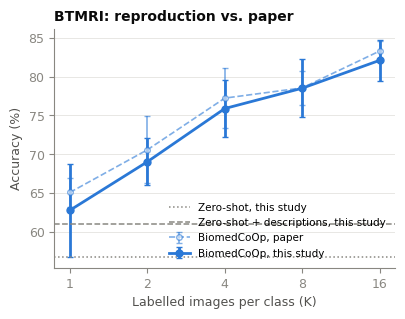

In [ ]:
fig, ax = plt.subplots(figsize=(4.4, 3.1))
for method in ['biomedcoop', 'coop']:
    label, colour, marker = STYLE[method]
    m = summary[(summary.method == method) & (summary.shots > 0)]
    if m.empty:
        continue
    p = PAPER[(PAPER.dataset == 'BTMRI') & (PAPER.method == method) & (PAPER.shots > 0)]
    ax.errorbar(p.shots, p.accuracy_mean, yerr=p.accuracy_std, color=colour, marker=marker,
                linestyle='--', linewidth=1.2, markersize=4, capsize=2, alpha=0.6,
                markerfacecolor='white', label=f'{label}, paper')
    ax.errorbar(m.shots, m.accuracy_mean, yerr=m.accuracy_std.fillna(0), color=colour,
                marker=marker, linewidth=2, markersize=5, capsize=2, label=f'{label}, this study')
for method, ls, name in [('zeroshot', ':', 'Zero-shot'), ('zeroshot_ensemble', '--', 'Zero-shot + descriptions')]:
    z = summary[summary.method == method]
    if not z.empty:
        ax.axhline(z.accuracy_mean.iloc[0], color=MUTED, linestyle=ls, linewidth=1.1,
                   label=f'{name}, this study')
shots_axis(ax)
ax.set_ylabel('Accuracy (%)')
ax.set_title('BTMRI: reproduction vs. paper', loc='left')
ax.legend(fontsize=7.5)
save(fig, 'btmri_reproduction')

The tables are saved in `placement2/results` on Drive and the full logs of every run in `placement2/outputs/BTMRI`.

In [ ]:
# Figures and table for the BTMRI reproduction. These cells only read what is
# already on Drive (run logs and confusion matrices), so nothing is retrained.
import glob, os, re
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

OUTPUTS = '/content/drive/MyDrive/placement2/outputs'
RESULTS = '/content/drive/MyDrive/placement2/results'
FIGS = f'{RESULTS}/figures'
os.makedirs(FIGS, exist_ok=True)

# Paper values (Table S8 of the supplementary material).
PAPER_ZS, PAPER_ZS_ENS = 56.79, 61.04
PAPER_BIOMEDCOOP = pd.DataFrame({'shots': [1, 2, 4, 8, 16],
                                 'mean': [65.08, 70.57, 77.23, 78.55, 83.30],
                                 'std': [1.81, 4.31, 3.90, 2.19, 1.34]})
SHOTS = [1, 2, 4, 8, 16]
TUMOURS = ['glioma tumor', 'meningioma tumor', 'normal brain', 'pituitary tumor']
SHORT = ['Glioma', 'Meningioma', 'Normal', 'Pituitary']


INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e4e3df'
MINE, PAPER = '#2a78d6', '#eb6834'
CLASS_COLOURS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
CLASS_MARKERS = ['o', 's', '^', 'D']
plt.rcParams.update({
    'font.size': 9, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK2,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.titlesize': 10, 'axes.titleweight': 'bold',
    'axes.titlecolor': INK, 'legend.frameon': False, 'savefig.dpi': 300,
    'savefig.bbox': 'tight'})


def read_log(run_dir):
    """Final test accuracy, macro-F1 and per-class accuracy from a run's logs."""
    text = ''.join(open(f, errors='ignore').read() for f in sorted(glob.glob(f'{run_dir}/log.txt*')))
    acc = re.findall(r'\* accuracy: ([\d.]+)%', text)
    if not acc:
        return None
    row = {'accuracy': float(acc[-1]), 'macro_f1': float(re.findall(r'\* macro_f1: ([\d.]+)%', text)[-1])}
    for name, a in re.findall(r'\* class: \d+ \((.+?)\).*?acc: ([\d.]+)%', text[text.rfind('* macro_f1'):]):
        row[name] = float(a)
    return row


def shots_axis(ax):
    ax.grid(axis='y', color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.set_xscale('log', base=2)
    ax.set_xticks(SHOTS, [str(k) for k in SHOTS])
    ax.set_xlim(0.8, 20)
    ax.set_xlabel('Labelled images per class (K)')


def save(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(f'{FIGS}/{name}.{ext}')
    plt.show()


# Read every BiomedCoOp run and the two zero-shot runs.
rows = []
for k in SHOTS:
    for seed in (1, 2, 3):
        r = read_log(f'{OUTPUTS}/BTMRI/biomedcoop/shots_{k}/seed{seed}')
        if r:
            rows.append({'shots': k, 'seed': seed, **r})
runs = pd.DataFrame(rows)
zs = read_log(f'{OUTPUTS}/BTMRI/zeroshot')
zs_ens = read_log(f'{OUTPUTS}/BTMRI/zeroshot_ensemble')
mine = runs.groupby('shots').agg(mean=('accuracy', 'mean'), std=('accuracy', 'std'),
                                 f1=('macro_f1', 'mean'), f1_std=('macro_f1', 'std'),
                                 n=('seed', 'count')).reset_index()
print(f'{len(runs)} BiomedCoOp runs read')

15 BiomedCoOp runs read


In [ ]:
table = mine.merge(PAPER_BIOMEDCOOP, on='shots', suffixes=('_mine', '_paper'))
table['difference'] = table.mean_mine - table.mean_paper
table['within_1_std'] = table.difference.abs() <= table[['std_mine', 'std_paper']].max(axis=1)

zs_rows = pd.DataFrame([
    {'method': 'Zero-shot BiomedCLIP', 'K': 0, 'paper': f'{PAPER_ZS:.2f}', 'this study': f"{zs['accuracy']:.2f}",
     'difference': f"{zs['accuracy'] - PAPER_ZS:+.2f}", 'macro-F1 (this study)': f"{zs['macro_f1']:.2f}"},
    {'method': 'Zero-shot + 50 descriptions', 'K': 0, 'paper': f'{PAPER_ZS_ENS:.2f}',
     'this study': f"{zs_ens['accuracy']:.2f}", 'difference': f"{zs_ens['accuracy'] - PAPER_ZS_ENS:+.2f}",
     'macro-F1 (this study)': f"{zs_ens['macro_f1']:.2f}"}])
bc_rows = pd.DataFrame({
    'method': 'BiomedCoOp', 'K': table.shots,
    'paper': [f'{m:.2f} ± {s:.2f}' for m, s in zip(table.mean_paper, table.std_paper)],
    'this study': [f'{m:.2f} ± {s:.2f}' for m, s in zip(table.mean_mine, table.std_mine)],
    'difference': [f'{d:+.2f}' for d in table.difference],
    'macro-F1 (this study)': [f'{m:.2f} ± {s:.2f}' for m, s in zip(table.f1, table.f1_std)]})
report_table = pd.concat([zs_rows, bc_rows], ignore_index=True)

report_table.to_csv(f'{RESULTS}/BTMRI_reproduction_table.csv', index=False)
runs.to_csv(f'{RESULTS}/BTMRI_biomedcoop_runs.csv', index=False)
print('Test accuracy (%) on BTMRI, mean ± std over seeds 1-3')
display(report_table.style.hide(axis='index'))

Test accuracy (%) on BTMRI, mean ± std over seeds 1-3


method,K,paper,this study,difference,macro-F1 (this study)
Zero-shot BiomedCLIP,0,56.79,56.79,+0.00,50.61
Zero-shot + 50 descriptions,0,61.04,61.04,+0.00,58.58
BiomedCoOp,1,65.08 ± 1.81,62.78 ± 5.99,-2.30,61.61 ± 4.00
BiomedCoOp,2,70.57 ± 4.31,69.03 ± 3.05,-1.54,68.63 ± 3.34
BiomedCoOp,4,77.23 ± 3.90,75.89 ± 3.63,-1.34,75.25 ± 3.81
BiomedCoOp,8,78.55 ± 2.19,78.51 ± 3.71,-0.04,77.76 ± 3.81
BiomedCoOp,16,83.30 ± 1.34,82.10 ± 2.63,-1.20,81.44 ± 2.44


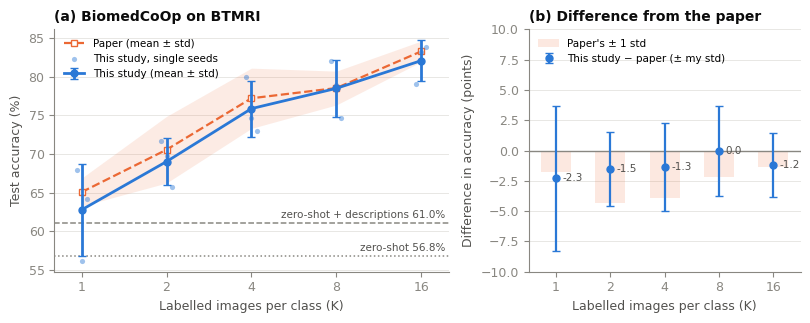

In [ ]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(8.2, 3.3), gridspec_kw={'width_ratios': [1.45, 1]})

# (a) My runs against the paper's mean ± std band, with the zero-shot levels as reference lines.
p = PAPER_BIOMEDCOOP
ax.fill_between(p.shots, p['mean'] - p['std'], p['mean'] + p['std'], color=PAPER, alpha=0.13, linewidth=0)
ax.plot(p.shots, p['mean'], color=PAPER, linestyle='--', linewidth=1.6, marker='s', markersize=5,
        markerfacecolor='white', label='Paper (mean ± std)')
jitter = {1: -0.06, 2: 0.0, 3: 0.06}   # small sideways shift so the three seeds don't overlap
ax.scatter([k * 2 ** jitter[s] for k, s in zip(runs.shots, runs.seed)], runs.accuracy,
           s=14, color=MINE, alpha=0.45, linewidth=0, label='This study, single seeds', zorder=3)
ax.errorbar(mine.shots, mine['mean'], yerr=mine['std'], color=MINE, marker='o', markersize=5,
            linewidth=2, capsize=3, label='This study (mean ± std)', zorder=4)
for value, ls, text in [(zs['accuracy'], ':', 'zero-shot'), (zs_ens['accuracy'], '--', 'zero-shot + descriptions')]:
    ax.axhline(value, color=MUTED, linestyle=ls, linewidth=1.1, zorder=1)
    ax.text(19.5, value + 0.4, f'{text} {value:.1f}%', ha='right', va='bottom', fontsize=7.5, color=INK2)
shots_axis(ax)
ax.set_ylabel('Test accuracy (%)')
ax.set_title('(a) BiomedCoOp on BTMRI', loc='left')
ax.legend(fontsize=7.5, loc='upper left')

# (b) How far my mean is from the paper's. The shaded bars are the paper's own
# seed-to-seed spread, so a point inside them is within normal run-to-run variation.
bx.axhline(0, color=MUTED, linewidth=1)
bx.bar(range(5), p['std'], bottom=-p['std'], width=0.55, color=PAPER, alpha=0.15, linewidth=0,
       label="Paper's ± 1 std")
bx.errorbar(range(5), table.difference, yerr=table.std_mine, color=MINE, marker='o', markersize=5,
            linestyle='none', capsize=3, linewidth=1.6, label='This study − paper (± my std)')
for i, d in enumerate(table.difference):
    bx.text(i + 0.12, d, f'{d:+.1f}' if abs(d) >= 0.05 else '0.0', va='center', fontsize=7.5, color=INK2)
bx.set_xticks(range(5), [str(k) for k in SHOTS])
bx.set_xlabel('Labelled images per class (K)')
bx.set_ylabel('Difference in accuracy (points)')
bx.grid(axis='y', color=GRID, linewidth=0.6)
bx.set_axisbelow(True)
bx.set_title('(b) Difference from the paper', loc='left')
bx.legend(fontsize=7.5, loc='upper left')
lim = max(8, np.ceil((table.difference.abs() + table.std_mine).max()) + 1)
bx.set_ylim(-lim, lim)
fig.tight_layout()
save(fig, 'btmri_reproduction')

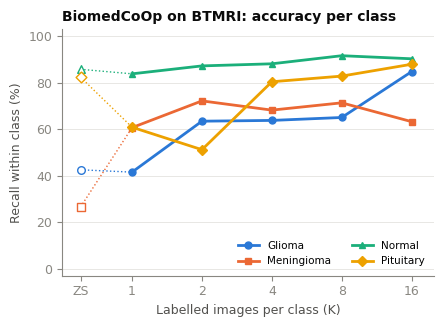

In [ ]:
# Mean of the three seeds. The hollow markers at "ZS" are zero-shot with the
# 50 descriptions, i.e. where each class starts before any training.
fig, ax = plt.subplots(figsize=(4.8, 3.2))
per_class = runs.groupby('shots')[TUMOURS].mean()
ZS_X = 0.6
for name, short, colour, marker in zip(TUMOURS, SHORT, CLASS_COLOURS, CLASS_MARKERS):
    ax.plot(per_class.index, per_class[name], color=colour, marker=marker, markersize=5,
            linewidth=2, label=short)
    ax.plot([ZS_X, 1], [zs_ens[name], per_class[name].iloc[0]], color=colour, linestyle=':', linewidth=1)
    ax.scatter(ZS_X, zs_ens[name], marker=marker, s=30, facecolor='white', edgecolor=colour, zorder=3)
shots_axis(ax)
ax.set_xlim(0.5, 20)
ax.set_xticks([ZS_X] + SHOTS, ['ZS'] + [str(k) for k in SHOTS])
ax.set_ylim(-3, 103)
ax.set_ylabel('Recall within class (%)')
ax.set_title('BiomedCoOp on BTMRI: accuracy per class', loc='left')
ax.legend(fontsize=7.5, ncol=2, loc='lower right')
save(fig, 'btmri_per_class')

In [ ]:
# Software and hardware used, for the Methods section.
import platform, torch, torchvision, transformers, numpy, sklearn, subprocess
versions = {
    'Python': platform.python_version(),
    'PyTorch': torch.__version__,
    'torchvision': torchvision.__version__,
    'transformers': transformers.__version__,
    'numpy': numpy.__version__,
    'scikit-learn': sklearn.__version__,
    'GPU': torch.cuda.get_device_name(0),
    'BiomedCoOp commit': subprocess.run(['git', '-C', BIOMEDCOOP, 'rev-parse', 'HEAD'],
                                        capture_output=True, text=True).stdout.strip(),
}
pd.Series(versions).to_csv(f'{RESULTS}/software_versions.csv', header=False)
pd.Series(versions)

/usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(


,0
Python,3.13.16
PyTorch,2.11.0+cu130
torchvision,0.26.0+cu130
transformers,4.35.2
numpy,2.4.6
scikit-learn,1.6.1
GPU,Tesla T4
BiomedCoOp commit,23710b0b867e8cb4a5ea95b0ccbaa5e35203db0d


In [ ]:
from scipy import stats
rows = []
for _, r in table.iterrows():
    t, p_value = stats.ttest_ind_from_stats(r.mean_mine, r.std_mine, 3,
                                            r.mean_paper, r.std_paper, 3, equal_var=False)
    rows.append({'K': int(r.shots), 'this study': f'{r.mean_mine:.2f} ± {r.std_mine:.2f}',
                 'paper': f'{r.mean_paper:.2f} ± {r.std_paper:.2f}',
                 'difference': round(r.difference, 2), 't': round(t, 2), 'p': round(p_value, 2)})
welch = pd.DataFrame(rows)
welch.to_csv(f'{RESULTS}/BTMRI_welch_tests.csv', index=False)
welch

,K,this study,paper,difference,t,p
0,1,62.78 ± 5.99,65.08 ± 1.81,-2.30,-0.64,0.58
1,2,69.03 ± 3.05,70.57 ± 4.31,-1.54,-0.50,0.64
2,4,75.89 ± 3.63,77.23 ± 3.90,-1.34,-0.44,0.69
3,8,78.51 ± 3.71,78.55 ± 2.19,-0.04,-0.02,0.99
4,16,82.10 ± 2.63,83.30 ± 1.34,-1.20,-0.70,0.53
